# Using MultiModal

In [1]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
import os

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\Chetan Sri Reddy\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\transformers\training_args.py:1594: FutureWarning: `evaluation_strategy` is deprecated and will be removed in version 4.46 of 🤗 Transformers. Use `eval_strategy` instead
  warnings.warn(


Training...


Step,Training Loss
500,0.152000


Evaluating...


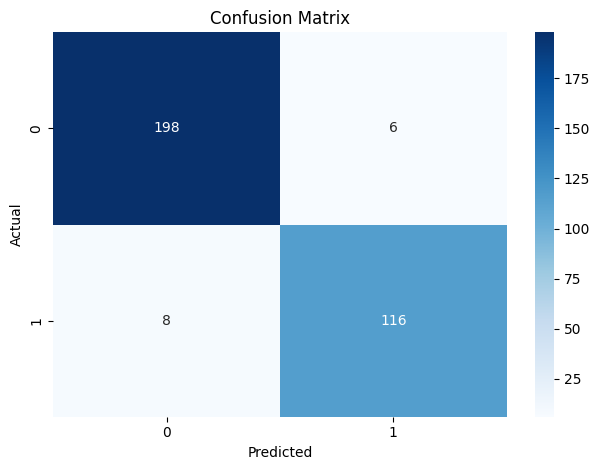

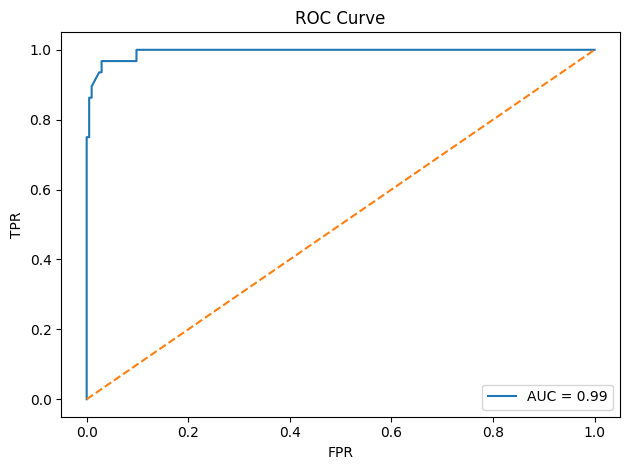


Final Metrics:
Accuracy: 0.9573
F1 Score: 0.9431
Precision: 0.9508
Recall: 0.9355


In [2]:
# Set device
device = torch.device('cpu')

# Load dataset
# Load dataset
df = pd.read_csv(r"D:\SDP\Phishing\EMAIL\Copy of Phishing_Email(1).csv", low_memory=False)

# Select only required columns
df = df[['Email Text', 'Email Type']].dropna()

# Map label and rename
df['Email Type'] = df['Email Type'].map({'Phishing Email': 1, 'Safe Email': 0})
df = df.dropna(subset=['Email Type'])
df = df.rename(columns={'Email Type': 'Label'})
df['Label'] = df['Label'].astype(int)

# Sample data
df = df.sample(frac=0.5, random_state=42)

# ✅ Correct label column name here
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df['Email Text'], df['Label'], test_size=0.2, random_state=42
)


# Tokenize
tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased", use_fast=True)
model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2).to(device)

train_encodings = tokenizer(list(train_texts), truncation=True, padding=True, max_length=64)
test_encodings = tokenizer(list(test_texts), truncation=True, padding=True, max_length=64)

# Convert to HuggingFace Dataset
train_dataset = Dataset.from_dict({
    "input_ids": train_encodings["input_ids"],
    "attention_mask": train_encodings["attention_mask"],
    "labels": train_labels.tolist()
})
test_dataset = Dataset.from_dict({
    "input_ids": test_encodings["input_ids"],
    "attention_mask": test_encodings["attention_mask"],
    "labels": test_labels.tolist()
})

# Training Args
training_args = TrainingArguments(
    output_dir="./results",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=4,
    weight_decay=0.1,
    evaluation_strategy="no",
    save_strategy="no",
    logging_dir="./logs",
    report_to="none"
)

# Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

print("Training...")
trainer.train()

# Save model
save_dir = r"D:\SDP\Phishing\EMAIL\model\distilbert_phishing_model"
os.makedirs(save_dir, exist_ok=True)
torch.save(model.state_dict(), os.path.join(save_dir, "distilbert_phishing_model.pth"))
tokenizer.save_pretrained(save_dir)

# Evaluate
print("Evaluating...")
preds = trainer.predict(test_dataset)
y_pred = preds.predictions.argmax(axis=-1)
y_true = test_labels.to_numpy()

# Metrics
accuracy = accuracy_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, preds.predictions[:, 1])
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.title("ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.legend()
plt.tight_layout()
plt.show()

# Final Metrics
print(f"\nFinal Metrics:\nAccuracy: {accuracy:.4f}\nF1 Score: {f1:.4f}\nPrecision: {precision:.4f}\nRecall: {recall:.4f}")


# Validation of MultiModal

In [10]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch.nn.functional as F

# Set device
device = torch.device("cpu")

# Load the tokenizer and model
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load the fine-tuned weights
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
model.load_state_dict(torch.load("D:/SDP/Phishing/EMAIL/model/distilbert_phishing_model/distilbert_phishing_model.pth", map_location=device))

model.to(device)
model.eval()

# Classification function
def classify_email(email_text):
    inputs = tokenizer(email_text, return_tensors="pt", truncation=True, padding=True, max_length=64)
    inputs.pop("token_type_ids", None)  # Remove token_type_ids if present
    inputs = {k: v.to(device) for k, v in inputs.items()}
    
    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=1)
        pred_class = torch.argmax(probs, dim=1).item()
        confidence = probs[0][pred_class].item()

    label = "Phishing Email" if pred_class == 1 else "Safe Email"
    return label, confidence

# Take user input for the email
user_email = input("Please enter the email text for classification:\n")

# Classify the user-provided email
label, confidence = classify_email(user_email)

# Output the prediction result
print(f"Prediction of the given Mail: {label}")


Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\Chetan Sri Reddy\AppData\Local\Temp\ipykernel_15372\1654299995.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mod

Please enter the email text for classification:
 "  "


Prediction of the given Mail: Phishing Email


model.safetensors:   0%|          | 0.00/286M [00:00<?, ?B/s]